<a href="https://colab.research.google.com/github/GAEL328530/Lab-pdi-PR-CTICAS/blob/main/Pr%C3%A1ctica_5_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ejercicio 1

Primero importo las librerías que voy a usar: OpenCV para trabajar con la imagen, NumPy para la matriz y Matplotlib para mostrar los resultados.

In [26]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Cargo la imagen en escala de grises y saco sus dimensiones (alto y ancho). Si no la encuentra, el programa avisa para no seguir con errores confusos.

In [27]:
imagen = cv2.imread("/content/Perro.jpg", cv2.IMREAD_GRAYSCALE)

if imagen is None:
    raise FileNotFoundError("No se encontró /content/Perro.jpg, hay que subirla primero")

alto, ancho = imagen.shape

Defino la matriz de traslación para mover la imagen 50 px a la derecha y 30 px hacia abajo, y la aplico con una transformación afín manteniendo el tamaño original.

In [28]:
tx, ty = 50, 30
M = np.float32([[1, 0, tx], [0, 1, ty]])

imagen_trasladada = cv2.warpAffine(imagen, M, (ancho, alto))

Por último, muestro la imagen original y la trasladada lado a lado para comparar el desplazamiento.

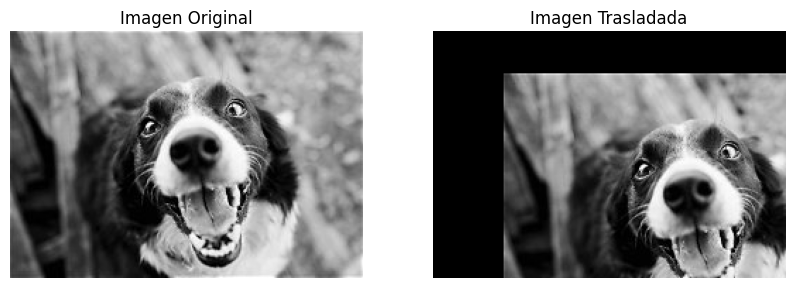

In [29]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_trasladada, cmap="gray")
plt.title("Imagen Trasladada")
plt.axis("off")

plt.show()

Ejercicio 2

Importo las librerías que voy a usar: OpenCV para trabajar con la imagen, NumPy para la matriz y Matplotlib para mostrar los resultados.

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Cargo la imagen en escala de grises y saco sus dimensiones (alto y ancho). Si no la encuentra, el programa avisa para no seguir con errores confusos.

In [31]:
imagen = cv2.imread("/content/Perro.jpg", cv2.IMREAD_GRAYSCALE)

if imagen is None:
    raise FileNotFoundError("No se encontró /content/Perro.jpg, hay que subirla primero")

alto, ancho = imagen.shape

Defino la matriz de traslación con valores decimales (100.5 px en X y 100.7 px en Y). Como el desplazamiento no cae en píxeles exactos, uso interpolación lineal (INTER_LINEAR) para calcular los valores intermedios al aplicar la transformación.

In [32]:
tx, ty = 100.5, 100.7
M = np.float32([[1, 0, tx], [0, 1, ty]])

imagen_trasladada = cv2.warpAffine(imagen, M, (ancho, alto), flags=cv2.INTER_LINEAR)

Por último, muestro la imagen original y la trasladada con decimales lado a lado para comparar el desplazamiento.

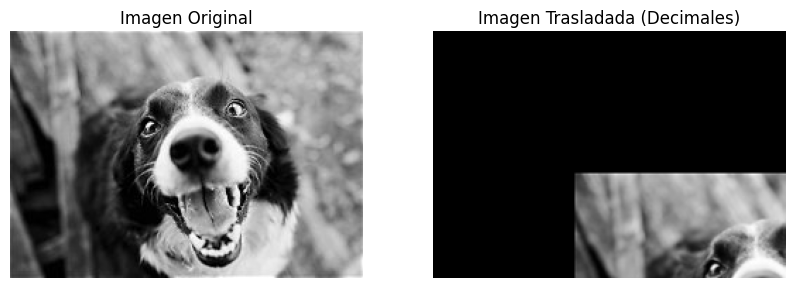

In [33]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_trasladada, cmap="gray")
plt.title("Imagen Trasladada (Decimales)")
plt.axis("off")

plt.show()

Ejercicio 3

Importo las librerías que voy a usar: OpenCV para trabajar con la imagen, NumPy para las matrices y Matplotlib para mostrar los resultados.

In [34]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Cargo la imagen en escala de grises y saco sus dimensiones (alto y ancho). Si no la encuentra, el programa avisa para no seguir con errores confusos.

In [35]:
imagen = cv2.imread("/content/Perro.jpg", cv2.IMREAD_GRAYSCALE)

if imagen is None:
    raise FileNotFoundError("No se encontró /content/Perro.jpg, hay que subirla primero")

alto, ancho = imagen.shape

Primero aplico la traslación: defino la matriz para mover la imagen 50 px en X y 30 px en Y, y la aplico con una transformación afín manteniendo el tamaño original.

In [36]:
tx, ty = 50, 30
M_translacion = np.float32([[1, 0, tx], [0, 1, ty]])

imagen_trasladada = cv2.warpAffine(imagen, M_translacion, (ancho, alto))

Después aplico la rotación de 30° alrededor del centro de la imagen, sin cambiar la escala. La rotación se hace sobre la imagen que ya fue trasladada, así que el resultado final combina las dos transformaciones.

In [37]:
angulo = 30
centro = (ancho // 2, alto // 2)
escala = 1.0

M_rotacion = cv2.getRotationMatrix2D(centro, angulo, escala)

imagen_final = cv2.warpAffine(imagen_trasladada, M_rotacion, (ancho, alto))

Por último, muestro las tres imágenes lado a lado: la original, la trasladada y la trasladada con rotación, para ver cómo cambia en cada paso.

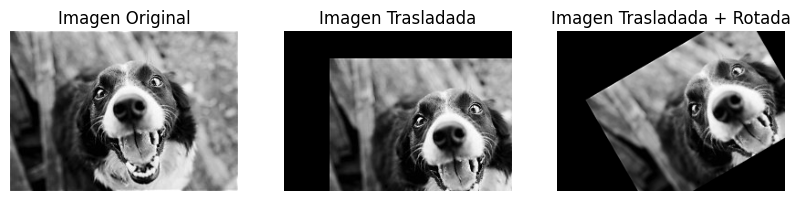

In [38]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_trasladada, cmap="gray")
plt.title("Imagen Trasladada")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_final, cmap="gray")
plt.title("Imagen Trasladada + Rotada")
plt.axis("off")

plt.show()

Ejercicio 4

Importo las librerías que voy a usar: OpenCV para trabajar con la imagen, NumPy para las matrices y Matplotlib para mostrar los resultados.

In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Cargo la imagen en escala de grises y saco sus dimensiones (alto y ancho). Si no la encuentra, el programa avisa para no seguir con errores confusos.

In [40]:
imagen = cv2.imread("/content/Perro.jpg", cv2.IMREAD_GRAYSCALE)

if imagen is None:
    raise FileNotFoundError("No se encontró /content/Perro.jpg, hay que subirla primero")

alto, ancho = imagen.shape

Primero aplico la traslación: defino la matriz para mover la imagen 50 px en X y 30 px en Y, y la aplico con una transformación afín manteniendo el tamaño original.

In [41]:
tx, ty = 50, 30
M_translacion = np.float32([[1, 0, tx], [0, 1, ty]])

imagen_trasladada = cv2.warpAffine(imagen, M_translacion, (ancho, alto))

Después aplico la rotación y el escalado en una sola matriz: giro 30° alrededor del centro de la imagen y la reduzco a 0.8 de su tamaño. Esto se hace sobre la imagen ya trasladada, así que el resultado final combina las tres transformaciones.

In [42]:
angulo = 30
escala = 0.8
centro = (ancho // 2, alto // 2)

M_rotacion_escala = cv2.getRotationMatrix2D(centro, angulo, escala)

imagen_final = cv2.warpAffine(imagen_trasladada, M_rotacion_escala, (ancho, alto))

Por último, muestro las tres imágenes lado a lado: la original, la trasladada y la que tiene traslación, rotación y escala, para ver cómo cambia en cada paso.

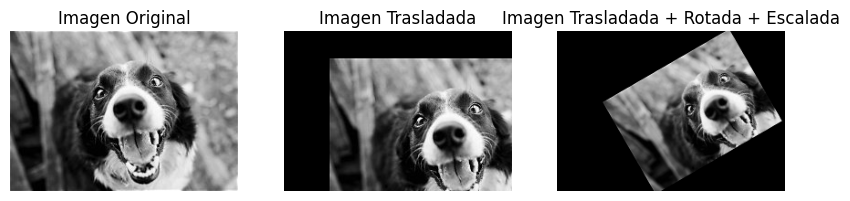

In [43]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_trasladada, cmap="gray")
plt.title("Imagen Trasladada")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_final, cmap="gray")
plt.title("Imagen Trasladada + Rotada + Escalada")
plt.axis("off")

plt.show()

Ejercicio 5

Importo las librerías que voy a usar: OpenCV para trabajar con la imagen, NumPy para las matrices y Matplotlib para mostrar los resultados.

In [44]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Transformación afín

Cargo la imagen en escala de grises y defino tres puntos de origen con sus tres puntos de destino. Con ellos OpenCV calcula la matriz de la transformación afín y la aplico manteniendo el tamaño original. Si la imagen no se encuentra, el programa avisa para no seguir con errores confusos.

In [45]:
imagen = cv2.imread("/content/Perro.jpg", cv2.IMREAD_GRAYSCALE)

if imagen is None:
    raise FileNotFoundError("No se encontró /content/Perro.jpg, hay que subirla primero")

pts1 = np.float32([[50, 50], [200, 50], [50, 200]])
pts2 = np.float32([[10, 100], [200, 50], [100, 250]])

M = cv2.getAffineTransform(pts1, pts2)

filas, columnas = imagen.shape
imagen_transformada = cv2.warpAffine(imagen, M, (columnas, filas))

Muestro la imagen original junto a la que tiene la transformación afín para comparar el efecto.

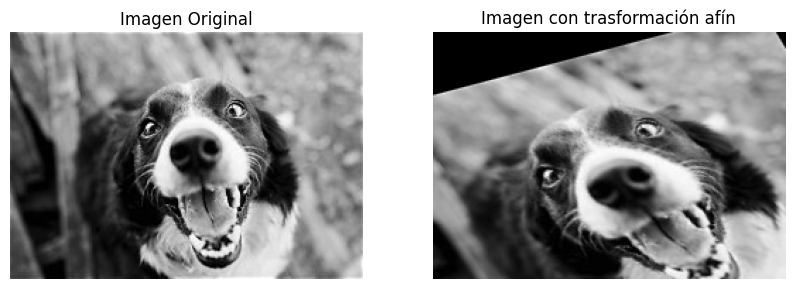

In [46]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_transformada, cmap="gray")
plt.title("Imagen con trasformación afín")
plt.axis("off")

plt.show()

## Transformación radial o distorsión radial

Defino la matriz de la cámara y los coeficientes de distorsión radial (son valores de ejemplo). Con eso calculo una nueva matriz óptima y corrijo la distorsión de la imagen.

In [47]:
K = np.array([[1000, 0, 640], [0, 1000, 360], [0, 0, 1]])
dist_coef = np.array([-0.2, 0.05, 0, 0, 0])

h, w = imagen.shape[:2]
new_K, roi = cv2.getOptimalNewCameraMatrix(K, dist_coef, (w, h), 1, (w, h))
imagen_corregida = cv2.undistort(imagen, K, dist_coef, None, new_K)

Por último, muestro la imagen original junto a la que pasó por la corrección radial.

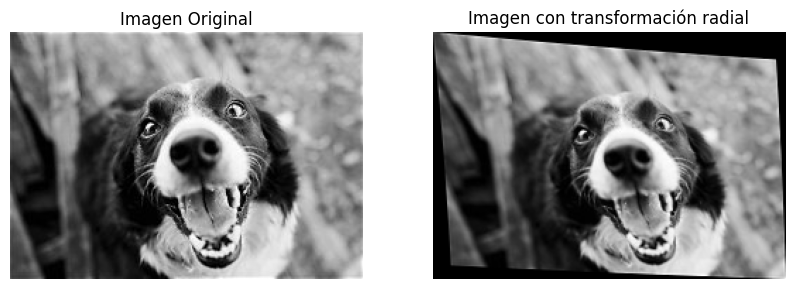

In [48]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_corregida, cmap="gray")
plt.title("Imagen con transformación radial")
plt.axis("off")

plt.show()